# Download dos datasets

## Importações

In [ ]:
from pathlib import Path
import tarfile
import urllib.request
import matplotlib.pyplot as plt
from torchvision import datasets

## Configurações

In [ ]:
# Cerâmica
URL_TILE = ("https://www.mydrive.ch/shares/163650/55ad2038770deff6fe6771bd784af8cc/"download/420938133-1629960456/tile.tar.xz")
PASTA_DATASET = Path("datasets/MVTecAD")
ARQUIVO_BAIXADO = Path("datasets/tile.tar.xz")
PASTA_DATASET.mkdir(parents=True, exist_ok=True)

# MNIST
PASTA_MNIST = Path("datasets/MNIST")
PASTA_MNIST.mkdir(parents=True, exist_ok=True)

# Download do dataset de cerâmicas

In [1]:
# Imprimir progresso
def progresso(blocos, tamanho_bloco, tamanho_total):
    if tamanho_total <= 0:
        return

    feito = min(blocos * tamanho_bloco, tamanho_total)
    porcentagem = 100 * feito / tamanho_total

    if blocos % 400 == 0 or feito == tamanho_total:
        print(f"  {porcentagem:5.1f}%  ({feito / 1e6:.0f} / {tamanho_total / 1e6:.0f} MB)")


ja_extraido = any((p / "train" / "good").exists() for p in PASTA_DATASET.rglob("tile"))
if ja_extraido:
    print("Dataset ja extraido. Nada a baixar.")

else:
    if not ARQUIVO_BAIXADO.exists():

        print("Baixando tile.tar.xz (~335 MB)...")

        try:
            urllib.request.urlretrieve(URL_TILE, ARQUIVO_BAIXADO, progresso)

        except Exception as erro:
            if ARQUIVO_BAIXADO.exists():
                ARQUIVO_BAIXADO.unlink()
            raise RuntimeError(f"Falha no download automatico.\nErro original: {erro}")

    # Extrair

    print("Extraindo...")

    with tarfile.open(ARQUIVO_BAIXADO, "r:*") as arquivo:

        try:
            arquivo.extractall(PASTA_DATASET, filter="data")
        except TypeError:
            arquivo.extractall(PASTA_DATASET)


# Localizar e conferir a categoria tile
pastas_validas = [p for p in PASTA_DATASET.rglob("tile") if (p / "train" / "good").exists()]

if not pastas_validas:
    raise FileNotFoundError("Nao foi encontrada a estrutura tile/train/good.")

PASTA_TILE = pastas_validas[0]

# Printar resumo
print("\nMVTec AD (tile) pronto!")
print("Pasta:", PASTA_TILE)
print("\nImagens de treinamento (train/good):", len(list((PASTA_TILE / "train" / "good").glob("*.png"))))
print("Imagens de teste sem defeito (test/good):", len(list((PASTA_TILE / "test" / "good").glob("*.png"))))
print("\nDefeitos reais em test/:")
for pasta in sorted((PASTA_TILE / "test").iterdir()):
    if pasta.is_dir() and pasta.name != "good":
        print(f"  {pasta.name:14s}", len(list(pasta.glob("*.png"))), "imagens")
if PASTA_TILE != Path("datasets/MVTecAD/tile"):
    print("\nATENCAO: ajuste PASTA_TILE nos outros notebooks para:", PASTA_TILE)


Baixando tile.tar.xz (~335 MB)...
    0.0%  (0 / 351 MB)
    0.9%  (3 / 351 MB)
    1.9%  (7 / 351 MB)
    2.8%  (10 / 351 MB)
    3.7%  (13 / 351 MB)
    4.7%  (16 / 351 MB)
    5.6%  (20 / 351 MB)
    6.5%  (23 / 351 MB)
    7.5%  (26 / 351 MB)
    8.4%  (29 / 351 MB)
    9.3%  (33 / 351 MB)
   10.3%  (36 / 351 MB)
   11.2%  (39 / 351 MB)
   12.1%  (43 / 351 MB)
   13.1%  (46 / 351 MB)
   14.0%  (49 / 351 MB)
   14.9%  (52 / 351 MB)
   15.9%  (56 / 351 MB)
   16.8%  (59 / 351 MB)
   17.7%  (62 / 351 MB)
   18.7%  (66 / 351 MB)
   19.6%  (69 / 351 MB)
   20.5%  (72 / 351 MB)
   21.5%  (75 / 351 MB)
   22.4%  (79 / 351 MB)
   23.3%  (82 / 351 MB)
   24.3%  (85 / 351 MB)
   25.2%  (88 / 351 MB)
   26.1%  (92 / 351 MB)
   27.1%  (95 / 351 MB)
   28.0%  (98 / 351 MB)
   28.9%  (102 / 351 MB)
   29.9%  (105 / 351 MB)
   30.8%  (108 / 351 MB)
   31.7%  (111 / 351 MB)
   32.6%  (115 / 351 MB)
   33.6%  (118 / 351 MB)
   34.5%  (121 / 351 MB)
   35.4%  (125 / 351 MB)
   36.4%  (128 / 351 MB)


## Download do MNIST

100%|█████████████████████████████████████████████████████████████████████████████| 9.91M/9.91M [00:01<00:00, 5.36MB/s]
100%|██████████████████████████████████████████████████████████████████████████████| 28.9k/28.9k [00:00<00:00, 218kB/s]
100%|█████████████████████████████████████████████████████████████████████████████| 1.65M/1.65M [00:01<00:00, 1.61MB/s]
100%|█████████████████████████████████████████████████████████████████████████████████████| 4.54k/4.54k [00:00<?, ?B/s]


MNIST pronto!
Pasta: C:\JupyterLab\process_im\datasets\MNIST
Imagens de treinamento: 60000
Imagens de teste: 10000
Formato de cada imagem: (28, 28)


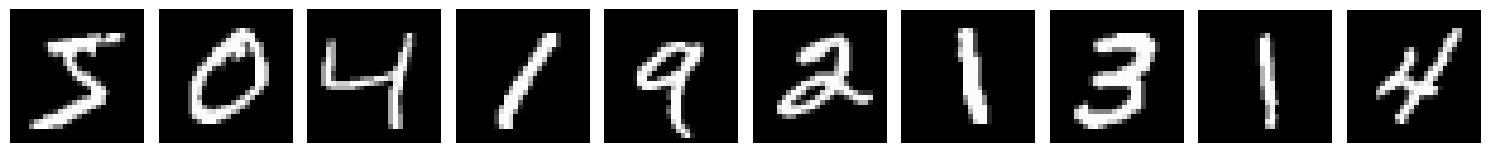

In [2]:
# Baixar
try:
    treino = datasets.MNIST(root=PASTA_MNIST, train=True, download=True)
    teste = datasets.MNIST(root=PASTA_MNIST, train=False, download=True)

except Exception as erro:
    raise RuntimeError(f"Falha ao baixar o MNIST. \nErro original: {erro}")

# Printar resumo
print("MNIST pronto!")
print("Pasta:", PASTA_MNIST.resolve())
print("Imagens de treinamento:", len(treino))
print("Imagens de teste:", len(teste))
print("Formato de cada imagem:", tuple(treino.data[0].shape))

# Exemplos
fig, eixos = plt.subplots(1, 10, figsize=(15, 2))

for i, eixo in enumerate(eixos):
    eixo.imshow(treino.data[i], cmap="gray")
    eixo.axis("off")

plt.tight_layout()
plt.show()
